# 02 · Research: the carry, the hedge, the risk model

Universe: every Binance USDT perp that traded Jan 2024 – Sep 2026, **delisted coins included**,
daily bars; tradable = 15 days of history and a trailing 30-day mean volume above $20m. BTC and
ETH define the market.

1. **Carry** - how much funding, how persistent, which forecast, does it pay a short.
2. **Hedge** - five definitions of the market beta, scored out of sample.
3. **Risk model** - the covariance matrix when there are more coins than days.

In [1]:
# run from the project root (works from research/ or any subfolder); the strategy package is
# in src/, the data download and plot style in research/lib
import os, sys
while not os.path.isdir("config") and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir("..")
sys.path[:0] = [os.path.abspath("src"), os.path.abspath("research/lib")]

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from betafunding import *
from plotstyle import *
apply()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
cfg = load_config()                     # the final strategy
SPEC = override(cfg, ORIGINAL_SPEC)     # the design as first specified
panel = load_panel(**cfg["data"])
BM = cfg["benchmarks"]
START = cfg["backtest"]["start"]

sig = build_signals(panel, override(SPEC, {"funding.forecast": "ema"}))
F, T = panel.funding, sig.eligible
Ft = F.where(T)
print(panel.close.shape, panel.close.index.min().date(), "->", panel.close.index.max().date(),
      "| tradable per day (median):", int(T.sum(axis=1).median()))

(1004, 667) 2024-01-01 -> 2026-09-30 | tradable per day (median): 142


## 1. Carry

### How much funding is there

145,796 tradable coin-days | at the 10.95% interest floor (±0.5): 29.6% | negative: 25.1% | above 50%: 5.3%


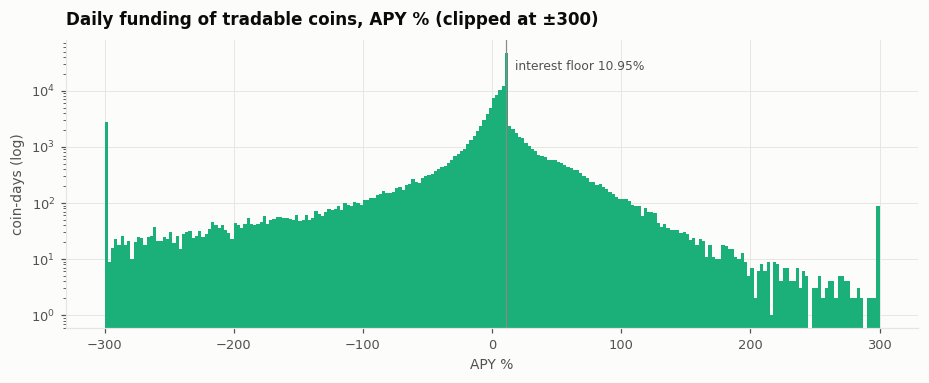

,0.01,0.05,0.25,0.50,0.75,0.95,0.99
APY %,-593.9,-79.7,-0.0,9.7,11.0,52.2,108.2


In [3]:
s = (Ft * APY).stack()
print(f"{len(s):,} tradable coin-days | at the 10.95% interest floor (±0.5): {((s - 10.95).abs() < .5).mean():.1%}"
      f" | negative: {(s < 0).mean():.1%} | above 50%: {(s > 50).mean():.1%}")
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(s.clip(-300, 300), bins=240, color=SERIES[2], log=True)
ax.axvline(10.95, color=MUTED, lw=0.8); ax.annotate("interest floor 10.95%", (10.95, ax.get_ylim()[1] * 0.3), xytext=(6, 0),
                                                   textcoords="offset points", fontsize=8, color=INK2)
ax.set_title("Daily funding of tradable coins, APY % (clipped at ±300)"); ax.set_xlabel("APY %"); ax.set_ylabel("coin-days (log)")
save(fig, "funding_distribution"); plt.show()
s.quantile([.01, .05, .25, .5, .75, .95, .99]).round(1).to_frame("APY %").T

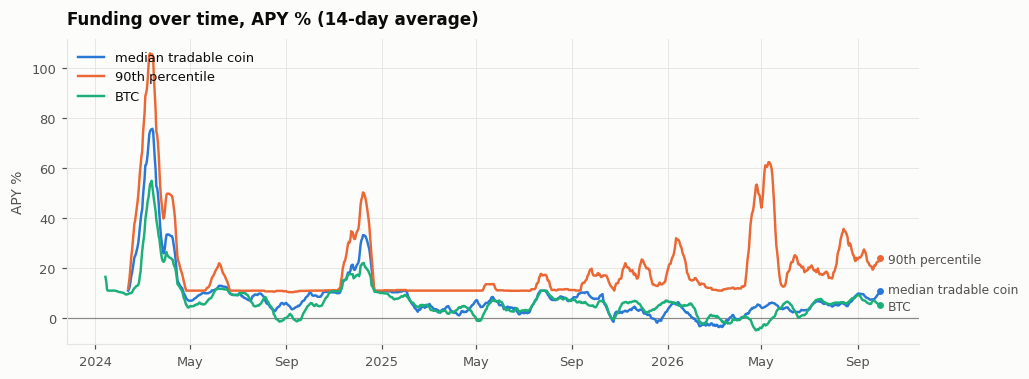

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
lines = {"median tradable coin": Ft.median(axis=1), "90th percentile": Ft.quantile(.9, axis=1), "BTC": F["BTC"]}
for (name, x), c in zip(lines.items(), SERIES):
    y = (x * APY).rolling(14).mean()
    ax.plot(y.index, y, color=c, label=name); end_label(ax, y, name, c)
zero(ax); ax.set_title("Funding over time, APY % (14-day average)"); ax.set_ylabel("APY %"); ax.legend(loc="upper left")
save(fig, "funding_over_time"); plt.show()

### How persistent, and which forecast (scored on tomorrow's funding)

1-day autocorrelation: median 0.60 -> half-life 1.4 days


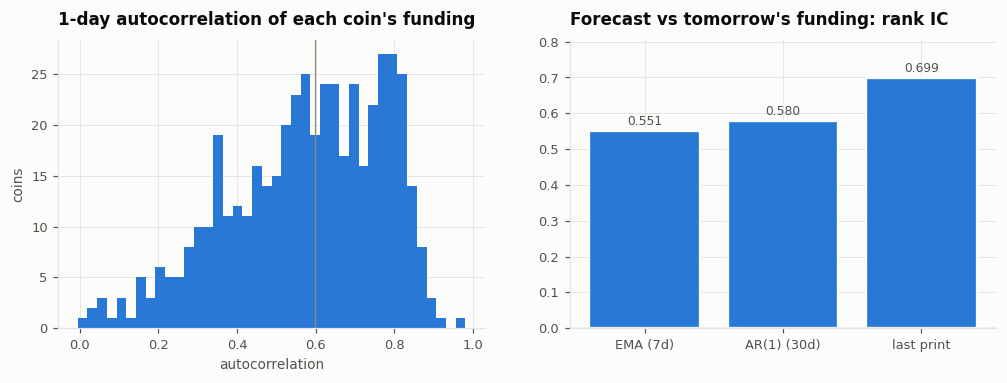

,RMSE_bps,rank_IC
EMA (7d),49.568,0.551
AR(1) (30d),51.381,0.580
last print,48.791,0.699


In [5]:
ac = pd.Series({c: Ft[c].dropna().autocorr(1) for c in Ft if Ft[c].notna().sum() > 60})
print(f"1-day autocorrelation: median {ac.median():.2f} -> half-life {np.log(.5)/np.log(ac.median()):.1f} days")
nxt = F.shift(-1)
rows = {}
for name, fc in {"EMA (7d)": funding_forecast(F, "ema", halflife=7),
                 "AR(1) (30d)": funding_forecast(F, "ar1", ar_window=30, ar_min_days=15),
                 "last print": F}.items():
    m = fc.notna() & nxt.notna() & T
    err = (fc - nxt).where(m)
    ics = []
    for d in F.index:
        a, b = fc.loc[d][m.loc[d]], nxt.loc[d][m.loc[d]]
        if len(a) >= 20 and a.std() > 0:
            ics.append(a.corr(b, method="spearman"))
    rows[name] = {"RMSE_bps": np.sqrt((err**2).stack().mean()) * 1e4, "rank_IC": np.mean(ics)}
fq = pd.DataFrame(rows).T
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(ac.dropna(), bins=40, color=SERIES[0]); axes[0].axvline(ac.median(), color=MUTED, lw=0.8)
axes[0].set_title("1-day autocorrelation of each coin's funding"); axes[0].set_xlabel("autocorrelation"); axes[0].set_ylabel("coins")
bars(axes[1], fq["rank_IC"], fmt="{:.3f}"); axes[1].set_title("Forecast vs tomorrow's funding: rank IC")
save(fig, "forecast_quality"); plt.show()
fq.round(3)

### Does high funding pay a short? (quintiles of yesterday's AR(1) forecast, BTC/ETH-hedged return)

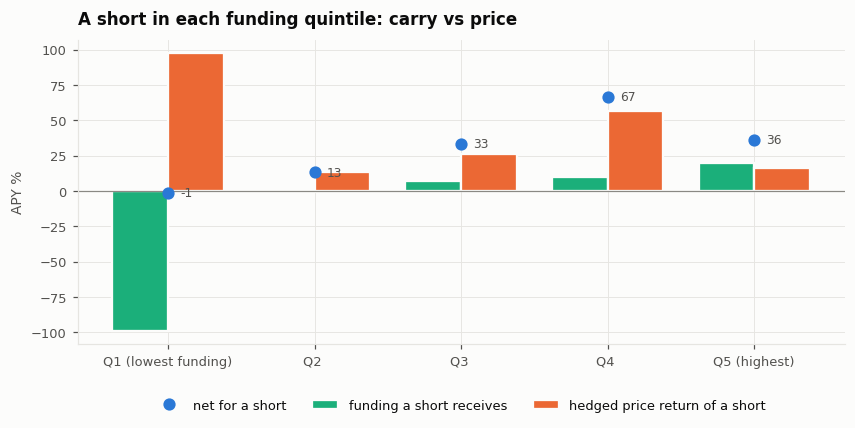

,hedged_ret,funding,short_net_APY
q,,,
1,-97.3,-98.7,-1.4
2,-13.7,-0.6,13.1
3,-26.5,7.0,33.5
4,-56.5,10.2,66.6
5,-16.4,19.8,36.2


In [6]:
fh = funding_forecast(F, "ar1", ar_window=30, ar_min_days=15)
_, _, exp = market_betas(panel.ret, "joint", 30, 15)
hedged = hedged_returns(panel.ret, exp)
q = []
for d in hedged.index[1:]:
    prev = d - pd.Timedelta(days=1)
    x = fh.loc[prev].where(T.loc[prev]); m = x.notna() & hedged.loc[d].notna()
    if m.sum() < 25: continue
    b = pd.qcut(x[m].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
    q.append(pd.DataFrame({"q": b, "hedged_ret": hedged.loc[d][m], "funding": F.loc[d][m]}))
q = pd.concat(q).groupby("q").mean() * APY
q["short_net_APY"] = -q["hedged_ret"] + q["funding"]
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(5); w = 0.38
r1 = ax.bar(x - w/2, q["funding"], w, color=PNL["funding"], edgecolor=SURFACE, lw=1.5, label="funding a short receives")
r2 = ax.bar(x + w/2, -q["hedged_ret"], w, color=PNL["price"], edgecolor=SURFACE, lw=1.5, label="hedged price return of a short")
ax.plot(x, q["short_net_APY"], "o", color=PNL["net"], ms=7, label="net for a short")
for i, v in enumerate(q["short_net_APY"]): ax.annotate(f"{v:.0f}", (i, v), xytext=(8, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
zero(ax); ax.set_xticks(x, [f"Q{i} {'(lowest funding)' if i == 1 else '(highest)' if i == 5 else ''}" for i in range(1, 6)])
ax.set_ylabel("APY %"); ax.set_title("A short in each funding quintile: carry vs price"); legend_below(ax)
save(fig, "quintiles"); plt.show()
q.round(1)

## 2. Hedge: five definitions of the market beta

`joint` = BTC and ETH in one regression, neutral to each; `btc` / `eth` = one coin; `combined` =
(BTC+ETH)/2; `adaptive` = per coin the better-fitting of BTC / ETH. Hedge with yesterday's betas,
share of each coin's daily variance removed.

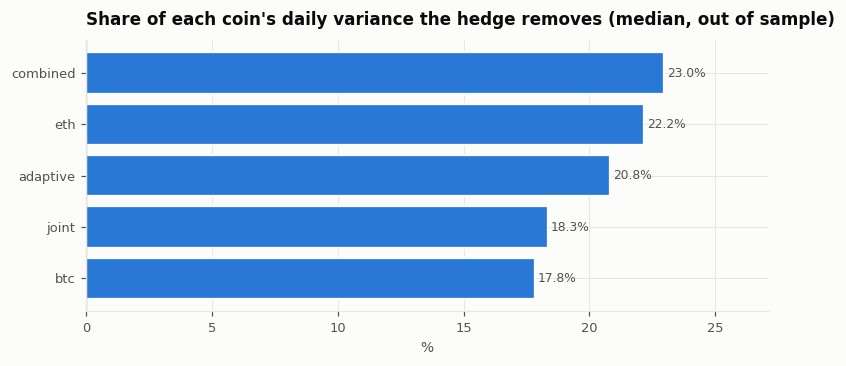

,median var removed %,coins worse off %,|corr| to BTC after,|corr| to ETH after
joint,18.339,29.253,0.060,0.063
btc,17.838,23.651,0.057,0.159
eth,22.171,21.577,0.075,0.064
combined,22.974,21.784,0.065,0.062
adaptive,20.817,25.934,0.062,0.061


In [7]:
rows = {}
for t in BETA_TYPES:
    betas, _, exp = market_betas(panel.ret, t, 30, 15)
    h = hedged_returns(panel.ret, exp)
    m = h.notna() & panel.ret.notna() & T.shift(1).fillna(False).astype(bool)
    red = (1 - h.where(m).var() / panel.ret.where(m).var())[m.sum() >= 60].dropna()
    rows[t] = {"median var removed %": red.median() * 100, "coins worse off %": (red < 0).mean() * 100,
               "|corr| to BTC after": h.where(m).corrwith(panel.ret["BTC"]).abs().median(),
               "|corr| to ETH after": h.where(m).corrwith(panel.ret["ETH"]).abs().median()}
hq = pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(8, 3.2))
bars(ax, hq["median var removed %"].sort_values(), horizontal=True, fmt="{:.1f}%")
ax.set_title("Share of each coin's daily variance the hedge removes (median, out of sample)"); ax.set_xlabel("%")
save(fig, "beta_hedge"); plt.show()
hq.round(3)

## 3. Risk model: more coins than days

The optimiser's risk term needs a covariance for N tradable coins from T days. With N in the
hundreds and T = 60, the sample covariance is singular; Ledoit–Wolf shrinks it toward a scaled
identity and stays invertible; EWMA (λ = 0.94) weights the last ~2 weeks and is noisier still.
Condition number λmax/λmin each month (∞ = singular).

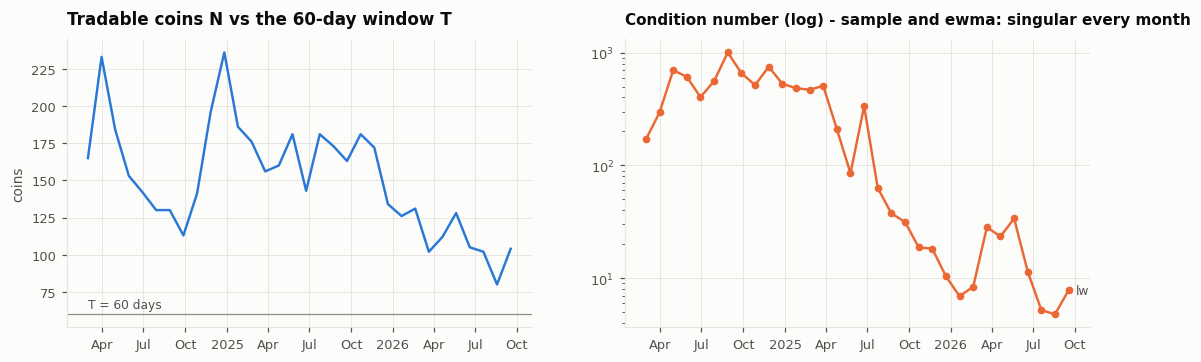

,N,sample,lw,ewma
mean,151,nan,268,nan
50%,148,nan,128,nan
max,236,nan,1e+03,nan


In [8]:
rows = []
for d in panel.close.index[60::30]:
    tick = list(T.columns[T.loc[d]])
    rv = sig.resid_var.loc[d, tick].fillna(0).to_numpy()
    row = {"date": d, "N": len(tick)}
    for mth in COV_MODELS:
        row[mth] = covariance(panel.ret, d, tick, rv, mth, 60)[1]
    rows.append(row)
cn = pd.DataFrame(rows).set_index("date")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(cn.index, cn["N"], color=SERIES[0]); axes[0].axhline(60, color=MUTED, lw=0.8)
axes[0].annotate("T = 60 days", (cn.index[0], 60), xytext=(0, 4), textcoords="offset points", fontsize=8, color=INK2)
axes[0].set_title("Tradable coins N vs the 60-day window T"); axes[0].set_ylabel("coins")
singular = [m for m in COV_MODELS if (cn[m] == np.inf).all()]
for mth, c in zip(COV_MODELS, SERIES):
    if mth in singular:
        continue
    y = cn[mth].replace(np.inf, np.nan)
    axes[1].semilogy(y.index, y, "o-", color=c, ms=4, label=mth); end_label(axes[1], y, mth, c)
axes[1].set_title(f"Condition number (log) - {' and '.join(singular)}: singular every month", fontsize=10)
save(fig, "condition_numbers"); plt.show()
cn.replace(np.inf, np.nan).describe().loc[["mean", "50%", "max"]].applymap(lambda x: f"{x:.3g}")

### Does the estimator change the book?

Same book (AR(1), joint beta, entry floor 10% APY, λ = 10), only the risk term changes:
per-coin residual variance (diag) vs a full covariance from the sample, Ledoit–Wolf or EWMA.

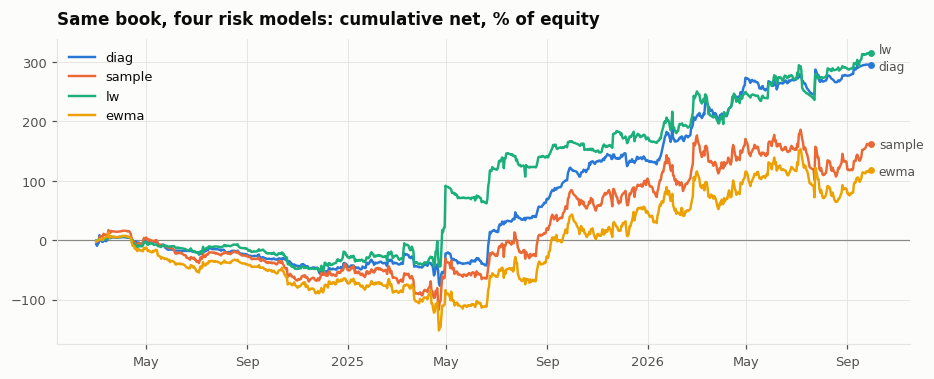

,diag,sample,lw,ewma
net_apy_%,114.11,62.79,121.44,45.63
funding_apy_%,209.89,338.09,234.46,311.59
price_apy_%,-85.53,-252.54,-102.98,-243.97
sharpe,1.62,0.59,1.20,0.45
ex_best10_%,96.60,-109.92,-4.20,-130.21
max_dd_compound_%,-62.46,-79.10,-53.31,-85.39
avg_gross,0.98,1.73,0.92,1.72
eff_n,11.87,11.87,14.56,12.10
avg_max_w,0.20,0.31,0.17,0.30
median_cond,NaN,inf,84.68,inf


In [9]:
base = SPEC
sig_ar1 = build_signals(panel, base)            # the book trades on the AR(1) forecast
rows, runs = {}, {}
for m in ("diag",) + COV_MODELS:
    c = override(base, {"risk.model": m})
    runs[m] = run(panel, sig_ar1, c, START)
    rows[m] = summarize(runs[m].daily, panel, BM, runs[m].weights)
fig, ax = plt.subplots(figsize=(10, 3.6))
for (m, r), c in zip(runs.items(), SERIES):
    y = r.daily["net"].cumsum() * 100
    ax.plot(y.index, y, color=c, label=m); end_label(ax, y, m, c)
zero(ax); ax.set_title("Same book, four risk models: cumulative net, % of equity"); ax.legend(loc="upper left")
save(fig, "risk_models"); plt.show()
pd.DataFrame(rows)[["diag", *COV_MODELS]].loc[["net_apy_%", "funding_apy_%", "price_apy_%", "sharpe", "ex_best10_%",
    "max_dd_compound_%", "avg_gross", "eff_n", "avg_max_w", "median_cond"]].astype(float).round(2)

## Findings

**Carry**
- 145,796 tradable coin-days: 30% sit on the 10.95% APY interest floor, 25% are negative, 5% are above 50% APY.
- Funding is persistent: median 1-day autocorrelation 0.60, a half-life of ~1.4 days.
- Forecast vs tomorrow's funding: AR(1) ranks better than an EMA (rank IC 0.58 vs 0.55), but **the last print is better than both** (IC 0.70, lowest RMSE). Funding moves slowly enough that today's value is a strong forecast.
- A short in each forecast quintile: the higher the funding, the more the short collects; net is positive from Q2 up, best in Q4 (+67% APY).

**Hedge** (out of sample, share of each coin's daily variance removed)
- combined (BTC+ETH)/2: 23.0% · eth: 22.2% · adaptive: 20.8% · joint: 18.3% · btc: 17.8%.
- On daily bars the single combined factor hedges best and leaves the fewest coins worse off (22% vs 29% for joint). Every definition removes only about a fifth: coin-specific moves dominate.

**Risk model**
- ~150 tradable coins against a 60-day window: the sample and EWMA covariances are singular in every month; Ledoit–Wolf stays invertible (median condition number 128).
- In the book (AR(1), floors 10% APY): **diagonal residual variance is best** - Sharpe 1.62, +97% without the best 10 days. Ledoit–Wolf has the smaller drawdown (−53% vs −62%) but Sharpe 1.20 and nothing left without its best days. Sample and EWMA lever up on noise (gross 1.7) and lose 110–130% without their best days.